# 2. Results

All models on the same test period. Differences smaller than the bootstrap interval or the range over seeds are not claims; three seeds give a range, not a confidence interval.

In [1]:
%matplotlib inline
from pipeline.notebook_support import *
import pandas as pd
import numpy as np
pd.set_option('display.width', 160)
fraud = load_results('results_fraud.csv')
account = load_results('results_account.csv')
print('config hash:', fraud['config_hash'].unique())

config hash: <StringArray>
['2098e521aa7d']
Length: 1, dtype: str


In [2]:
metrics = ['pr_auc', 'roc_auc', 'recall_at_fpr', 'cost', 'brier', 'ece']
seed_summary(fraud, metrics).round(3)

,model,pr_auc_mean,roc_auc_mean,recall_at_fpr_mean,cost_mean,brier_mean,ece_mean,pr_auc_min,roc_auc_min,recall_at_fpr_min,cost_min,brier_min,ece_min,pr_auc_max,roc_auc_max,recall_at_fpr_max,cost_max,brier_max,ece_max
0,account_tabular,0.514,0.944,0.587,98249.853,0.026,0.011,0.479,0.939,0.584,95556.871,0.021,0.005,0.571,0.951,0.590,102220.584,0.029,0.018
1,final_bag_tabular,0.692,0.953,0.634,94305.076,0.018,0.002,0.691,0.953,0.633,93363.700,0.018,0.002,0.692,0.954,0.635,95148.095,0.018,0.002
2,final_refit_tabular,0.713,0.958,NaN,NaN,0.017,0.001,0.712,0.958,NaN,NaN,0.017,0.001,0.714,0.958,NaN,NaN,0.017,0.002
3,final_tabular,0.548,0.946,0.599,96875.411,0.023,0.007,0.397,0.940,0.593,92202.271,0.019,0.003,0.635,0.952,0.604,100719.186,0.029,0.015
4,final_tuned_tabular,0.681,0.950,0.629,100369.512,0.018,0.002,0.679,0.949,0.627,99283.203,0.018,0.002,0.684,0.951,0.632,101093.553,0.018,0.003
5,fraud_only,0.347,0.839,0.303,156333.143,0.068,0.189,0.341,0.834,0.287,145274.331,0.063,0.172,0.356,0.848,0.318,164525.338,0.073,0.201
6,fraud_only_history,0.342,0.833,0.319,159939.603,0.071,0.194,0.325,0.829,0.297,147661.713,0.067,0.183,0.351,0.839,0.341,169756.300,0.075,0.208
7,graph_labels_tabular,0.520,0.914,0.460,117395.283,0.023,0.004,0.516,0.912,0.457,115979.533,0.023,0.004,0.524,0.916,0.463,119703.825,0.024,0.004
8,graph_shared_tabular,0.464,0.887,0.423,135126.542,0.025,0.005,0.457,0.882,0.416,132649.387,0.025,0.005,0.469,0.889,0.432,139356.595,0.025,0.006
9,history_stable_tabular,0.465,0.885,0.434,139487.131,0.025,0.005,0.456,0.881,0.428,129892.775,0.025,0.004,0.476,0.888,0.441,144652.160,0.025,0.005


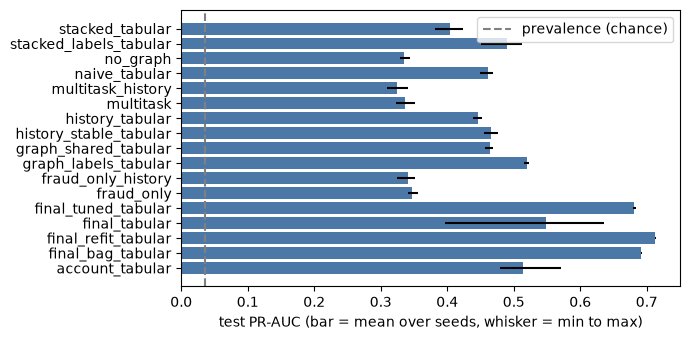

In [3]:
plot_pr_auc(fraud);

## Alert budgets

Recall, precision and the share of fraud *value* caught when only the top 0.5%, 1% or 5% of transactions can be reviewed.

In [4]:
cols = [c for c in fraud.columns if c.split('@')[0] in ('recall', 'precision', 'amount_recall') and '@' in c]
fraud.groupby('model')[cols].mean().round(3)

,recall@0.005,precision@0.005,amount_recall@0.005,recall@0.01,precision@0.01,amount_recall@0.01,recall@0.05,precision@0.05,amount_recall@0.05
model,,,,,,,,,
account_tabular,0.106,0.766,0.079,0.223,0.808,0.164,0.623,0.451,0.505
final_bag_tabular,0.136,0.980,0.100,0.260,0.941,0.205,0.706,0.511,0.616
final_refit_tabular,0.134,0.972,0.092,0.260,0.941,0.209,0.723,0.523,0.623
final_tabular,0.098,0.709,0.076,0.204,0.736,0.154,0.658,0.476,0.554
final_tuned_tabular,0.135,0.975,0.103,0.260,0.938,0.208,0.700,0.506,0.605
fraud_only,0.108,0.778,0.043,0.189,0.683,0.096,0.432,0.312,0.355
fraud_only_history,0.101,0.728,0.036,0.184,0.664,0.083,0.432,0.313,0.349
graph_labels_tabular,0.121,0.872,0.078,0.231,0.837,0.148,0.582,0.421,0.516
graph_shared_tabular,0.119,0.861,0.074,0.231,0.834,0.134,0.531,0.384,0.466


## Cost

Expected cost uses an assumed review cost per false alert (see the config); compare each model with flagging nothing.

In [5]:
fraud.groupby('model')[['cost', 'cost_flag_none', 'cost_flag_all']].mean().round(0)

,cost,cost_flag_none,cost_flag_all
model,,,
account_tabular,98250.0,370374.0,320990.0
final_bag_tabular,94305.0,370374.0,320990.0
final_refit_tabular,NaN,370374.0,320990.0
final_tabular,96875.0,370374.0,320990.0
final_tuned_tabular,100370.0,370374.0,320990.0
fraud_only,156333.0,370374.0,320990.0
fraud_only_history,159940.0,370374.0,320990.0
graph_labels_tabular,117395.0,370374.0,320990.0
graph_shared_tabular,135127.0,370374.0,320990.0


## Account-risk head and ablations

In [6]:
seed_summary(account, ['pr_auc', 'roc_auc']).round(3)

,model,pr_auc_mean,roc_auc_mean,pr_auc_min,roc_auc_min,pr_auc_max,roc_auc_max
0,account_only,0.216,0.778,0.207,0.771,0.225,0.788
1,hgb_user_aggregates,0.133,0.675,0.116,0.659,0.151,0.683
2,mean_fraud_score,0.452,0.857,0.439,0.850,0.471,0.862
3,multitask,0.246,0.775,0.220,0.771,0.264,0.780
4,multitask_history,0.270,0.792,0.256,0.777,0.278,0.807


## Over time and calibration

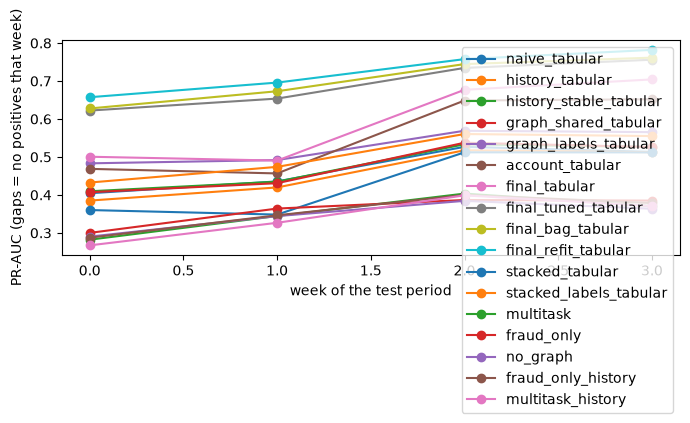

In [7]:
plot_weekly(load_results('results_weekly.csv'));

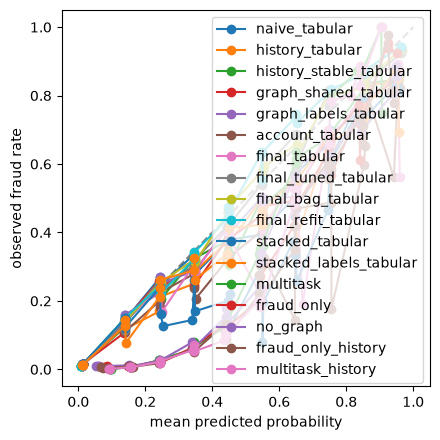

In [8]:
plot_calibration(load_results('calibration.csv'));